In [3]:
import mysql.connector

# CONNECT PYTHON WITH MYSQL DATABASE 

In [4]:
conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="root",
    database="banking_system"
)
print("connection established succesfully!")

cursor = conn.cursor()

query = "SELECT * FROM customers"

connection established succesfully!


# CHECK AVAILABLE TABLES IN THE DATABASE 

In [5]:
cursor.execute("SHOW TABLES")

In [6]:
# FETCHALL Get all query results

results = cursor.fetchall()

for row in results:
    print(row)

('branches',)
('customer_transactions',)
('customers',)
('transactions',)


In [7]:
# PANDAS-DATA HANDLING
# pd.read_sql()Read SQL data into Dataframe

import pandas as pd

query = "SELECT * FROM customers"
df = pd.read_sql(query, conn)  
print(df)

     customer_id customer_name        city       phone account_type email
0              1  Arun Prakash     Chennai  9876543240      Current  None
1              2      Bhavya R   Bangalore  9876543241      Current  None
2              3     Chandru K      Mumbai  9876543242      Savings  None
3              4     Dharani S  Coimbatore  9876543243      Savings  None
4              5      Elango M     Madurai  9876543244      Current  None
..           ...           ...         ...         ...          ...   ...
212          213     Yashika S     Madurai  9876543307      Current  None
213          214       Zubin R       Kochi  9876543308      Savings  None
214          215   Anand Kumar       Salem  9876543309      Savings  None
215          216   Bhanu Priya     Chennai  9876543310      Current  None
216          217      Charan S   Hyderabad  9876543311      Savings  None

[217 rows x 6 columns]


C:\Users\acer\AppData\Local\Temp\ipykernel_3268\1192254348.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


In [8]:
 import matplotlib.pyplot as plt
 import pandas as pd
 import seaborn as sns

In [9]:
query = "SELECT *FROM customers"
df = pd.read_sql(query, conn)

C:\Users\acer\AppData\Local\Temp\ipykernel_3268\1046188508.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


# Data Exploration

In [10]:
df.head()

,customer_id,customer_name,city,phone,account_type,email
0,1,Arun Prakash,Chennai,9876543240,Current,None
1,2,Bhavya R,Bangalore,9876543241,Current,None
2,3,Chandru K,Mumbai,9876543242,Savings,None
3,4,Dharani S,Coimbatore,9876543243,Savings,None
4,5,Elango M,Madurai,9876543244,Current,None


In [11]:
df.shape

(217, 6)

In [12]:
df.columns

Index(['customer_id', 'customer_name', 'city', 'phone', 'account_type',
       'email'],
      dtype='str')

In [13]:
df.dtypes

customer_id       int64
customer_name       str
city                str
phone               str
account_type        str
email            object
dtype: object

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 217 entries, 0 to 216
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customer_id    217 non-null    int64 
 1   customer_name  217 non-null    str   
 2   city           217 non-null    str   
 3   phone          217 non-null    str   
 4   account_type   217 non-null    str   
 5   email          0 non-null      object
dtypes: int64(1), object(1), str(4)
memory usage: 10.3+ KB


In [15]:
df.describe()

,customer_id
count,217.000000
mean,109.000000
std,62.786676
min,1.000000
25%,55.000000
50%,109.000000
75%,163.000000
max,217.000000


# Data Cleaning

In [16]:
df.isna().sum()

customer_id        0
customer_name      0
city               0
phone              0
account_type       0
email            217
dtype: int64

In [17]:
df.isna().sum()/len(df)*100

customer_id        0.0
customer_name      0.0
city               0.0
phone              0.0
account_type       0.0
email            100.0
dtype: float64

In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
df[df.duplicated()]

,customer_id,customer_name,city,phone,account_type,email


In [20]:
df['city'].unique()

<StringArray>
[   'Chennai',  'Bangalore',     'Mumbai', 'Coimbatore',    'Madurai',
      'Kochi',  'Hyderabad',    'Kolkata',      'Delhi',       'Pune',
      'Salem']
Length: 11, dtype: str

In [21]:
df['account_type'].unique()

<StringArray>
['Current', 'Savings']
Length: 2, dtype: str

In [22]:
transaction_query = "SELECT * FROM transactions"
transaction_df = pd.read_sql(transaction_query, conn)

C:\Users\acer\AppData\Local\Temp\ipykernel_3268\1331065444.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  transaction_df = pd.read_sql(transaction_query, conn)


# Data Exploration

In [23]:
transaction_df.head()

,transaction_id,customer_id,transaction_type,amount,transaction_date,payment_mode
0,211,31,Withdrawal,4500.0,2026-03-28,ATM
1,212,32,Deposit,36000.0,2026-04-01,UPI
2,213,33,Deposit,52000.0,2026-04-03,Bank Transfer
3,214,34,Withdrawal,2500.0,2026-04-05,ATM
4,215,35,Deposit,21000.0,2026-04-07,Cash


In [24]:
transaction_df.shape

(140, 6)

In [25]:
transaction_df.columns

Index(['transaction_id', 'customer_id', 'transaction_type', 'amount',
       'transaction_date', 'payment_mode'],
      dtype='str')

In [26]:
transaction_df.dtypes

transaction_id        int64
customer_id           int64
transaction_type        str
amount              float64
transaction_date     object
payment_mode            str
dtype: object

In [27]:
transaction_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 140 entries, 0 to 139
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   transaction_id    140 non-null    int64  
 1   customer_id       140 non-null    int64  
 2   transaction_type  140 non-null    str    
 3   amount            140 non-null    float64
 4   transaction_date  140 non-null    object 
 5   payment_mode      140 non-null    str    
dtypes: float64(1), int64(2), object(1), str(2)
memory usage: 6.7+ KB


In [28]:
transaction_df.describe()

,transaction_id,customer_id,amount
count,140.0000,140.000000,140.000000
mean,280.5000,65.500000,25935.714286
std,40.5586,20.277748,19862.281493
min,211.0000,31.000000,2500.000000
25%,245.7500,48.000000,5500.000000
50%,280.5000,65.500000,27000.000000
75%,315.2500,83.000000,43000.000000
max,350.0000,100.000000,63000.000000


# Data Cleaning

In [29]:
transaction_df.isna().sum()

transaction_id      0
customer_id         0
transaction_type    0
amount              0
transaction_date    0
payment_mode        0
dtype: int64

In [30]:
(transaction_df.isna().sum() / len(transaction_df)) * 100

transaction_id      0.0
customer_id         0.0
transaction_type    0.0
amount              0.0
transaction_date    0.0
payment_mode        0.0
dtype: float64

In [31]:
transaction_df['transaction_type'].unique()

<StringArray>
['Withdrawal', 'Deposit']
Length: 2, dtype: str

In [32]:
transaction_df.duplicated().sum()

np.int64(0)

In [33]:
transaction_df[transaction_df.duplicated()]

,transaction_id,customer_id,transaction_type,amount,transaction_date,payment_mode


In [34]:
# Amount Validation

transaction_df[transaction_df['amount'] <= 0]

,transaction_id,customer_id,transaction_type,amount,transaction_date,payment_mode


# Data Integration – Merging Customers & Transactions

In [35]:
merged_df = pd.merge(df, transaction_df,
    on='customer_id',
    how='inner'
)

In [36]:
merged_df.head()

,customer_id,customer_name,city,phone,account_type,email,transaction_id,transaction_type,amount,transaction_date,payment_mode
0,31,Girish Kumar,Chennai,9876543270,Savings,None,211,Withdrawal,4500.0,2026-03-28,ATM
1,31,Girish Kumar,Chennai,9876543270,Savings,None,281,Withdrawal,4500.0,2026-03-28,ATM
2,32,Harinath M,Coimbatore,9876543271,Current,None,212,Deposit,36000.0,2026-04-01,UPI
3,32,Harinath M,Coimbatore,9876543271,Current,None,282,Deposit,36000.0,2026-04-01,UPI
4,33,Ishwar R,Pune,9876543272,Savings,None,213,Deposit,52000.0,2026-04-03,Bank Transfer


In [37]:
merged_df.shape

(140, 11)

In [38]:
merged_df.columns

Index(['customer_id', 'customer_name', 'city', 'phone', 'account_type',
       'email', 'transaction_id', 'transaction_type', 'amount',
       'transaction_date', 'payment_mode'],
      dtype='str')

# Data Analysis – Transaction Type

In [39]:
merged_df['transaction_type'].value_counts()

transaction_type
Deposit       84
Withdrawal    56
Name: count, dtype: int64

In [40]:
merged_df.groupby('transaction_type')['amount'].sum()

transaction_type
Deposit       3364000.0
Withdrawal     267000.0
Name: amount, dtype: float64

# Data Analysis – Customer Transaction Summary

In [41]:
merged_df.groupby('customer_id')['amount'].sum().sort_values(ascending=False)

customer_id
60    126000.0
87    124000.0
45    122000.0
97    118000.0
40    116000.0
        ...   
48      6000.0
91      6000.0
76      6000.0
34      5000.0
69      5000.0
Name: amount, Length: 70, dtype: float64

# Data Analysis – City-Wise Transaction Amount

In [42]:
merged_df.groupby('city')['amount'].sum().sort_values(ascending=False)

city
Chennai       597000.0
Madurai       452000.0
Kolkata       407000.0
Kochi         382000.0
Mumbai        357000.0
Pune          347000.0
Bangalore     313000.0
Hyderabad     298000.0
Delhi         207000.0
Salem         171000.0
Coimbatore    100000.0
Name: amount, dtype: float64

In [43]:
merged_df['amount'].mean()

np.float64(25935.714285714286)

# Visualization – Transaction Amount Distribution

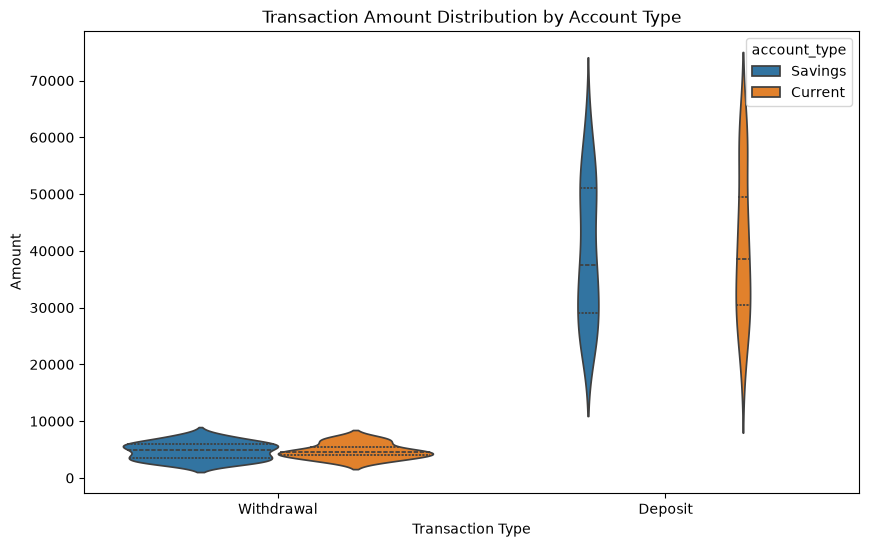

In [44]:
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=merged_df,
    x='transaction_type',
    y='amount',
    hue='account_type',
    inner='quartile'
)

plt.title('Transaction Amount Distribution by Account Type')
plt.xlabel('Transaction Type')
plt.ylabel('Amount')

plt.show()

# Visualization – City & Transaction Type Analysis

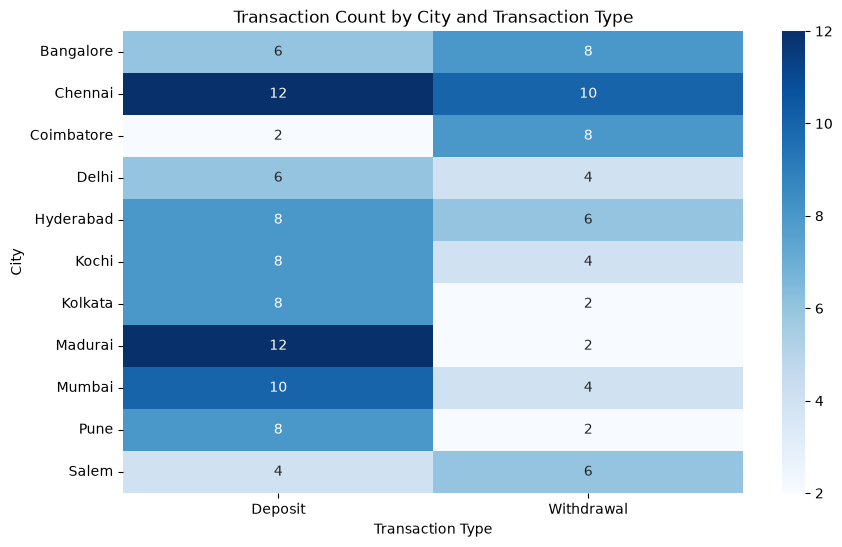

In [45]:
heatmap_data = pd.crosstab(
    merged_df['city'],
    merged_df['transaction_type']
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Transaction Count by City and Transaction Type')
plt.xlabel('Transaction Type')
plt.ylabel('City')

plt.show()

# Visualization – City-Wise Transaction Amount

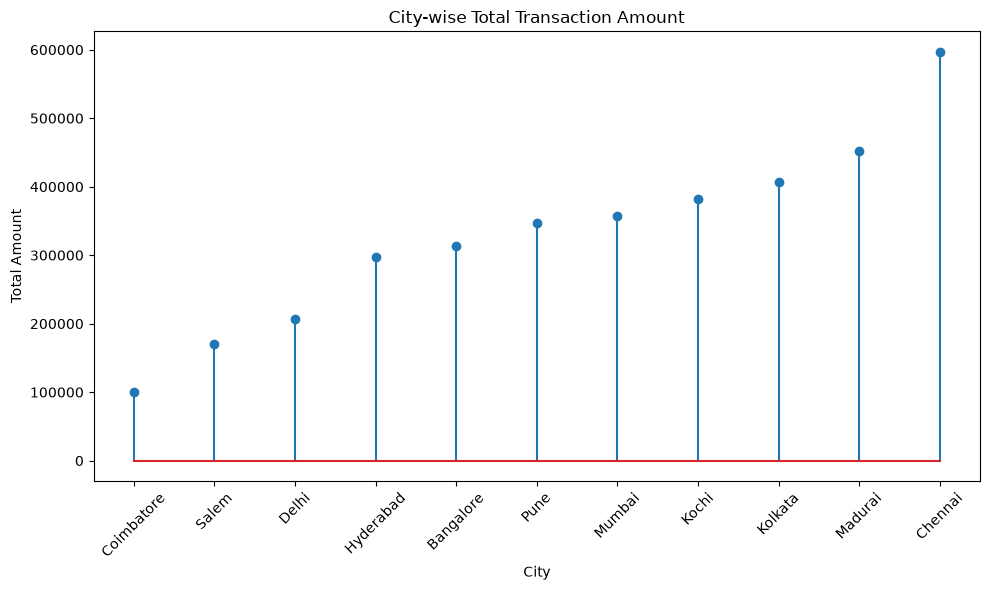

In [46]:
city_amount = (
    merged_df.groupby('city')['amount']
    .sum()
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 6))

plt.stem(
    city_amount.index,
    city_amount.values
)

plt.title('City-wise Total Transaction Amount')
plt.xlabel('City')
plt.ylabel('Total Amount')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Visualization – City-Wise Transaction Analysis

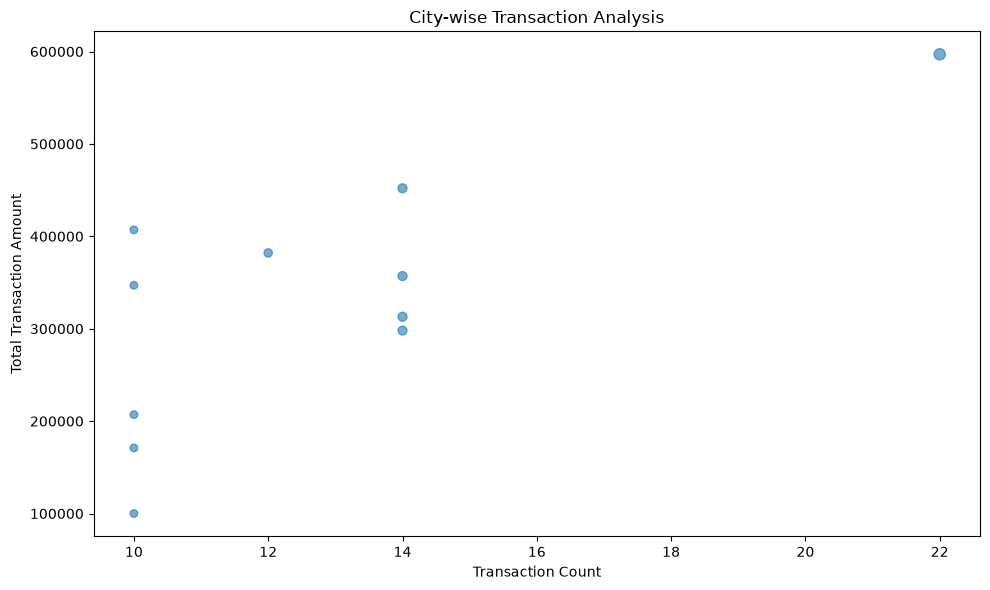

In [47]:
city_analysis = (
    merged_df.groupby('city')
    .agg(
        transaction_count=('transaction_type', 'count'),
        total_amount=('amount', 'sum')
    )
    .reset_index()
)

plt.figure(figsize=(10, 6))

plt.scatter(
    city_analysis['transaction_count'],
    city_analysis['total_amount'],
    s=city_analysis['transaction_count'] * 3,
    alpha=0.6
)

plt.title('City-wise Transaction Analysis')
plt.xlabel('Transaction Count')
plt.ylabel('Total Transaction Amount')

plt.tight_layout()
plt.show()

# Visualization – Transaction Flow Analysis

In [48]:
import plotly.graph_objects as go

city_list = merged_df['city'].unique().tolist()
transaction_list = merged_df['transaction_type'].unique().tolist()
account_list = merged_df['account_type'].unique().tolist()

labels = city_list + transaction_list + account_list

source = []
target = []
value = []

# City → Transaction Type
for city in city_list:
    for transaction in transaction_list:
        count = len(
            merged_df[
                (merged_df['city'] == city) &
                (merged_df['transaction_type'] == transaction)
            ]
        )
        if count > 0:
            source.append(labels.index(city))
            target.append(labels.index(transaction))
            value.append(count)

# Transaction Type → Account Type
for transaction in transaction_list:
    for account in account_list:
        count = len(
            merged_df[
                (merged_df['transaction_type'] == transaction) &
                (merged_df['account_type'] == account)
            ]
        )
        if count > 0:
            source.append(labels.index(transaction))
            target.append(labels.index(account))
            value.append(count)

fig = go.Figure(go.Sankey(
    node=dict(
        label=labels,
        pad=20,
        thickness=20
    ),
    link=dict(
        source=source,
        target=target,
        value=value
    )
))

fig.update_layout(
    title='Transaction Flow: City → Transaction → Account'
)

fig.write_html("sankey_chart.html", auto_open=True)

# Visualization – Transaction Amount Trend

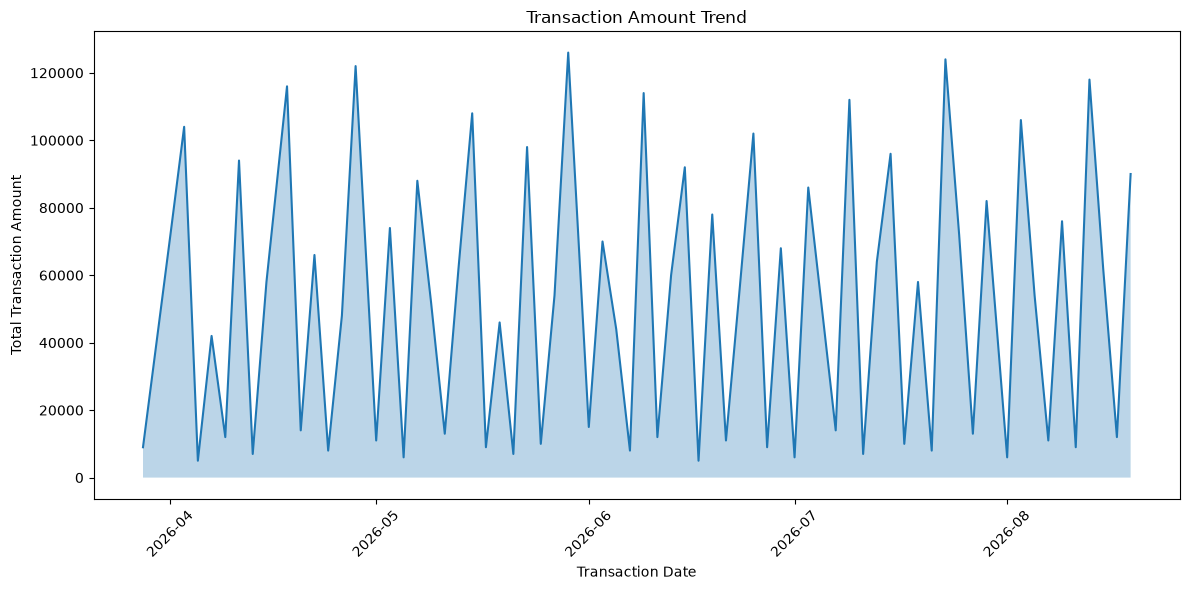

In [49]:
daily_amount = (
    merged_df.groupby('transaction_date')['amount']
    .sum()
    .sort_index()
)

plt.figure(figsize=(12, 6))

plt.plot(
    daily_amount.index,
    daily_amount.values
)

plt.fill_between(
    daily_amount.index,
    daily_amount.values,
    alpha=0.3
)

plt.title('Transaction Amount Trend')
plt.xlabel('Transaction Date')
plt.ylabel('Total Transaction Amount')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Visualization – Transaction Type Comparison

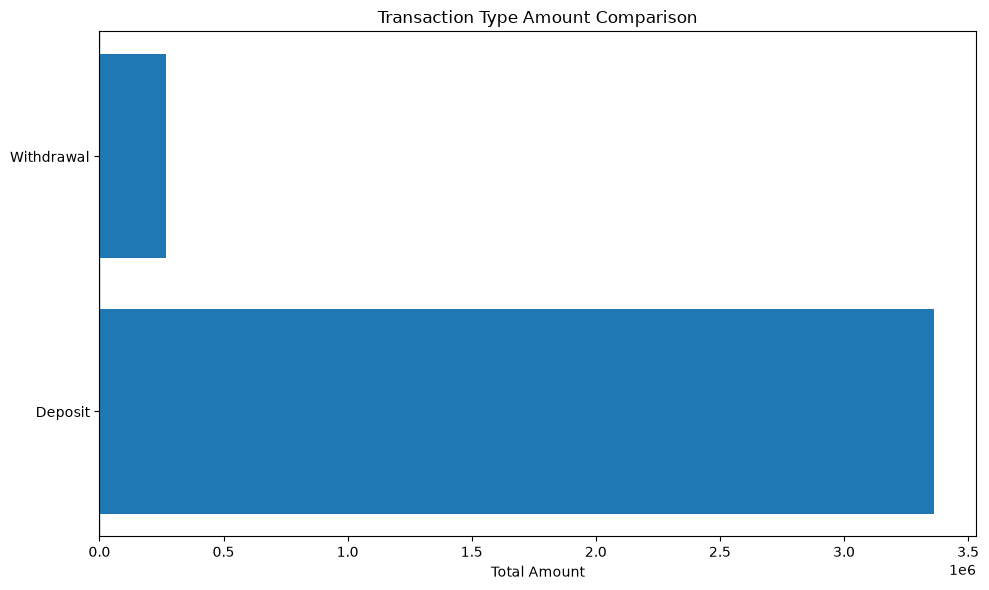

In [50]:
transaction_amount = (
    merged_df.groupby('transaction_type')['amount']
    .sum()
)

values = transaction_amount.values
labels = transaction_amount.index

plt.figure(figsize=(10, 6))

plt.barh(labels, values)

plt.axvline(0, linewidth=1)

plt.title('Transaction Type Amount Comparison')
plt.xlabel('Total Amount')

plt.tight_layout()
plt.show()

# Visualization – Account Type Distribution

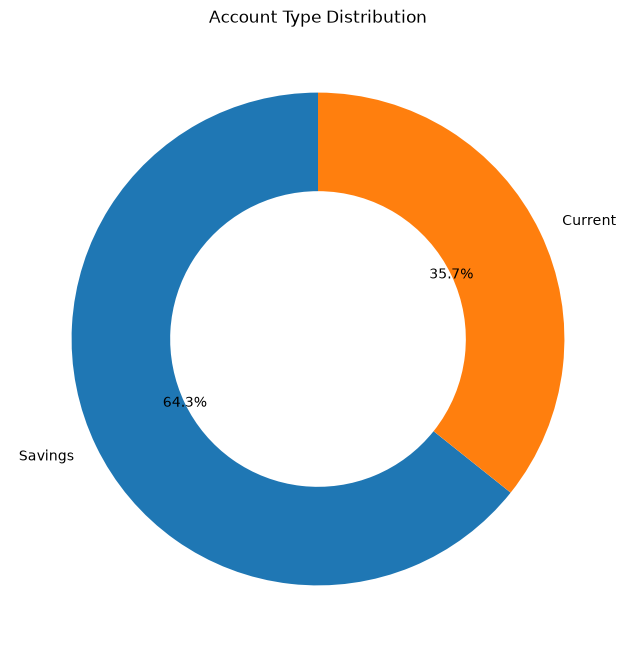

In [51]:
account_counts = merged_df['account_type'].value_counts()

plt.figure(figsize=(8, 8))

plt.pie(
    account_counts.values,
    labels=account_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'width': 0.4}
)

plt.title('Account Type Distribution')

plt.show()

# Visualization – Transaction Amount Spread

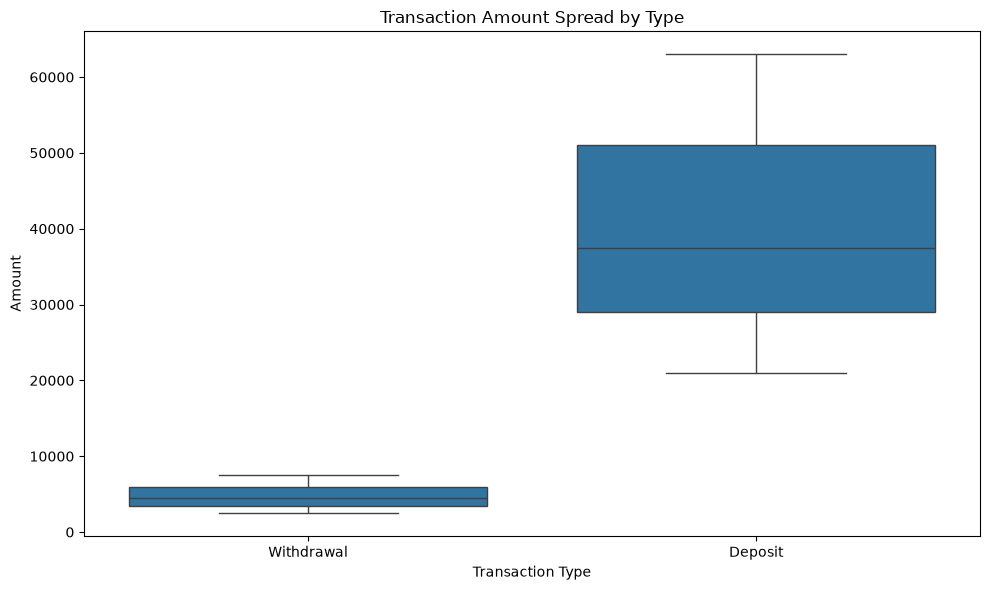

In [52]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=merged_df,
    x='transaction_type',
    y='amount'
)

plt.title('Transaction Amount Spread by Type')
plt.xlabel('Transaction Type')
plt.ylabel('Amount')

plt.tight_layout()
plt.show()

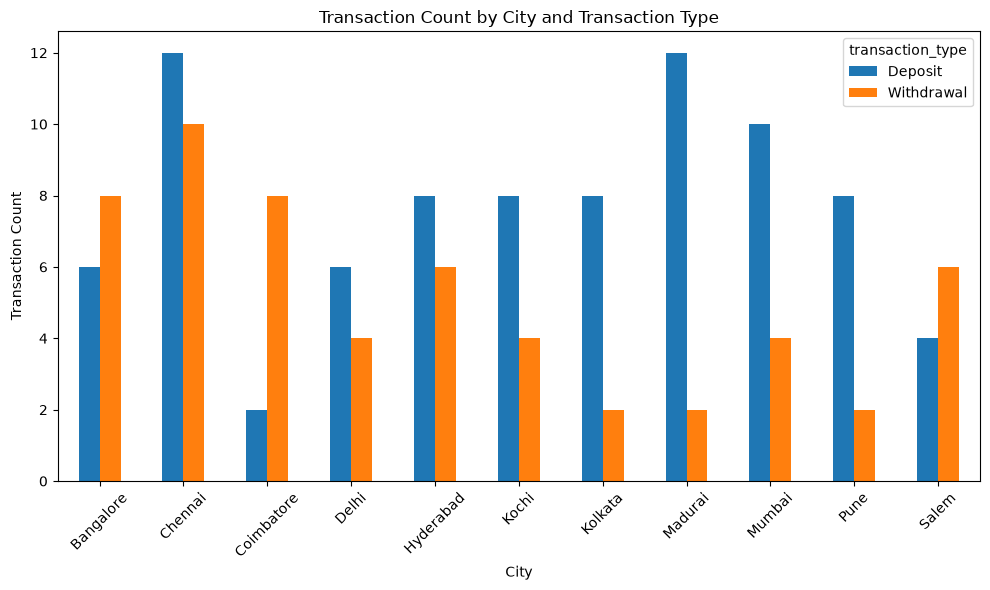

In [53]:
# Transaction Count by City and Transaction Type

city_transaction = (
    merged_df
    .groupby(['city', 'transaction_type'])
    .size()
    .unstack(fill_value=0)
)

city_transaction.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Transaction Count by City and Transaction Type')
plt.xlabel('City')
plt.ylabel('Transaction Count')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# BANKING TRANSACTION & CUSTOMER ANALYTICS DASHBOARD

In [54]:
# KPI Calculations

total_customers = merged_df['customer_id'].nunique()
total_transactions = len(merged_df)
total_amount = merged_df['amount'].sum()
average_amount = merged_df['amount'].mean()

print("Total Customers:", total_customers)
print("Total Transactions:", total_transactions)
print("Total Transaction Amount:", total_amount)
print("Average Transaction Amount:", average_amount)

Total Customers: 70
Total Transactions: 140
Total Transaction Amount: 3631000.0
Average Transaction Amount: 25935.714285714286


C:\Users\acer\AppData\Local\Temp\ipykernel_3268\53326639.py:153: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
C:\Users\acer\AppData\Local\Temp\ipykernel_3268\53326639.py:312: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


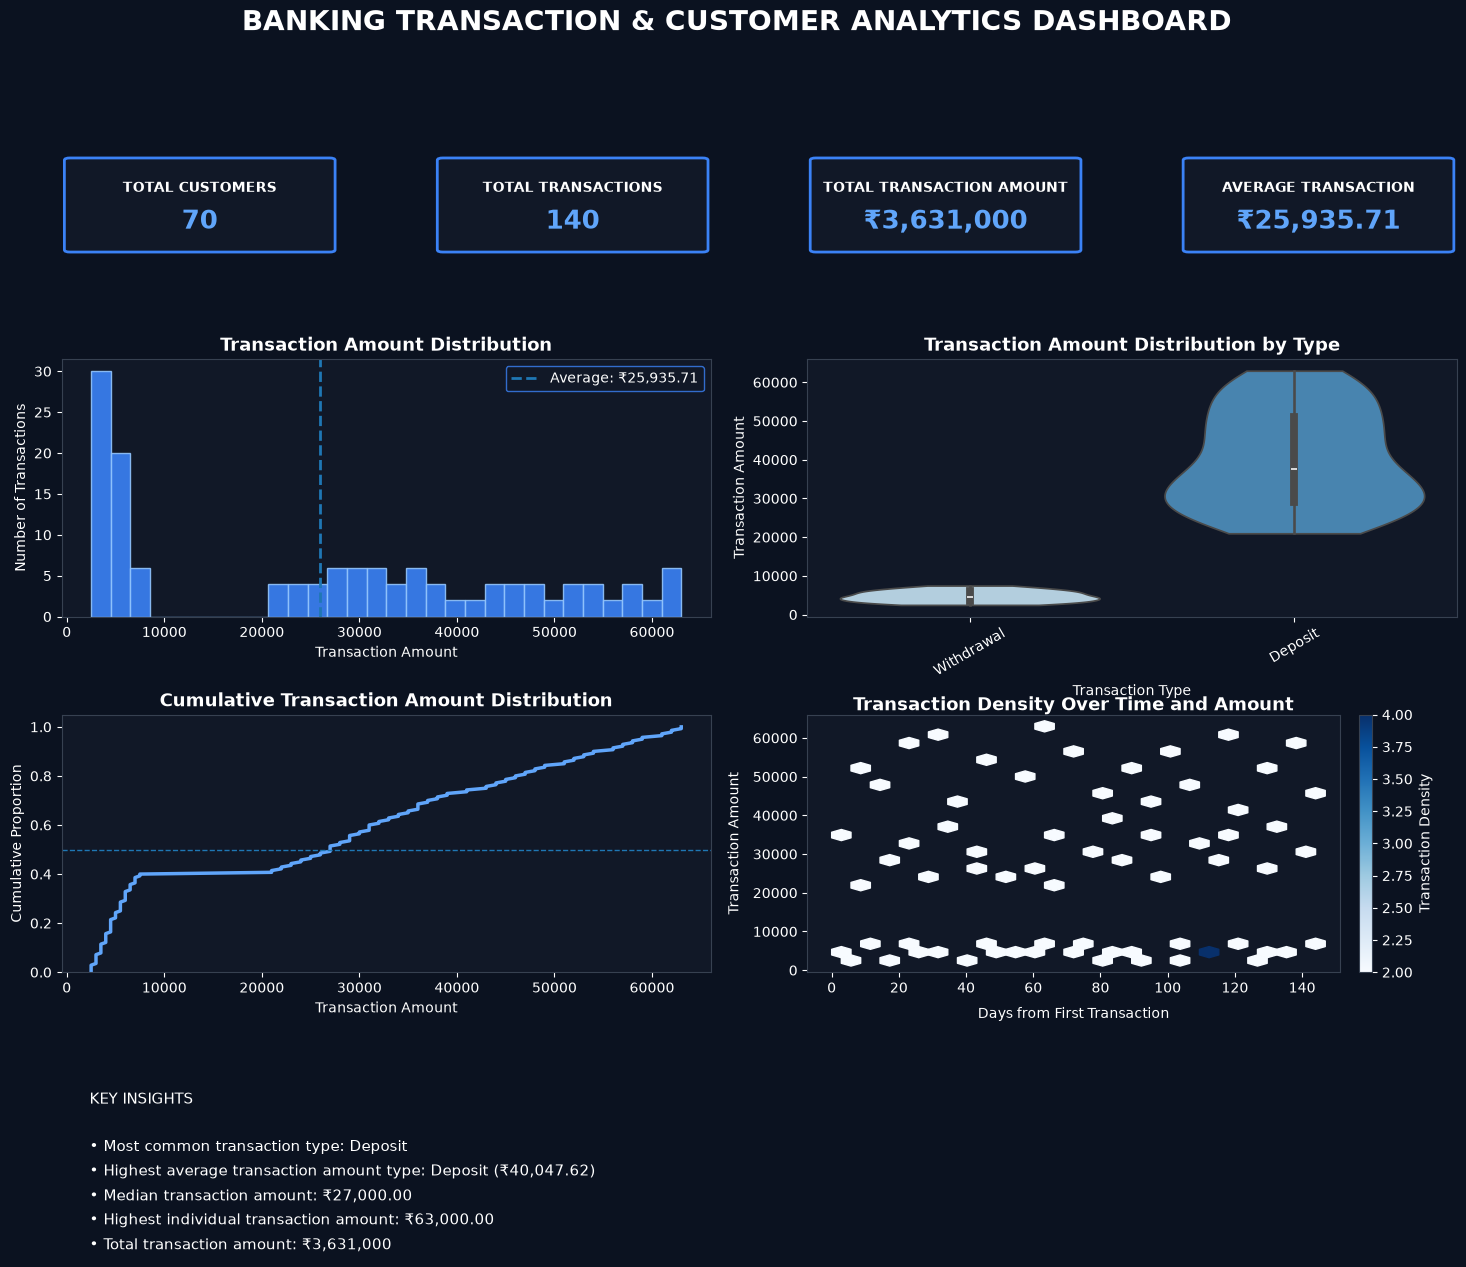

In [70]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import pandas as pd
import numpy as np
import seaborn as sns

# 1. DATA PREPARATION

df = merged_df.copy()

# Make sure transaction_date is datetime
df['transaction_date'] = pd.to_datetime(
    df['transaction_date'],
    errors='coerce'
)

# Remove invalid amount values
df = df.dropna(subset=['amount'])

# Remove negative amount values if present
df = df[df['amount'] >= 0]

# 2. KPI VALUES

total_customers = df['customer_id'].nunique()
total_transactions = len(df)
total_amount = df['amount'].sum()
average_amount = df['amount'].mean()

# 3. ADD NUMERIC DATE FOR HEXBIN

df['date_number'] = (
    df['transaction_date'] -
    df['transaction_date'].min()
).dt.total_seconds() / (60 * 60 * 24)
# PROFESSIONAL DARK THEME

plt.rcParams['figure.facecolor'] = '#0B1220'
plt.rcParams['axes.facecolor'] = '#111827'
plt.rcParams['text.color'] = 'white'
plt.rcParams['axes.labelcolor'] = 'white'
plt.rcParams['xtick.color'] = 'white'
plt.rcParams['ytick.color'] = 'white'
plt.rcParams['axes.edgecolor'] = '#374151'
plt.rcParams['legend.facecolor'] = '#111827'
plt.rcParams['legend.edgecolor'] = '#3B82F6'

# 4. CREATE DASHBOARD LAYOUT

fig = plt.figure(figsize=(18, 14))

gs = fig.add_gridspec(
    4,
    4,
    height_ratios=[1.0, 2.3, 2.3, 1.4],
    hspace=0.50,
    wspace=0.35
)

fig.suptitle(
    'BANKING TRANSACTION & CUSTOMER ANALYTICS DASHBOARD',
    fontsize=20,
    fontweight='bold',
    y=0.98
)

# 5. KPI CARDS

kpis = [
    ('TOTAL CUSTOMERS', f'{total_customers:,}'),
    ('TOTAL TRANSACTIONS', f'{total_transactions:,}'),
    ('TOTAL TRANSACTION AMOUNT', f'₹{total_amount:,.0f}'),
    ('AVERAGE TRANSACTION', f'₹{average_amount:,.2f}')
]

for i, (title, value) in enumerate(kpis):

    ax = fig.add_subplot(gs[0, i])
    ax.axis('off')

    box = FancyBboxPatch(
        (0.03, 0.10),
        0.94,
        0.80,
        boxstyle='round,pad=0.02',
        facecolor='#111827',
        edgecolor='#3B82F6',
        linewidth=2,
        transform=ax.transAxes
    )

    ax.add_patch(box)

    ax.text(
        0.50, 0.65, title,
        transform=ax.transAxes,
        ha='center',
        va='center',
        fontsize=10,
        fontweight='bold',
        color='white'
    )

    ax.text(
        0.50, 0.35, value,
        transform=ax.transAxes,
        ha='center',
        va='center',
        fontsize=19,
        fontweight='bold',
        color='#60A5FA'
    )

# 6. HISTOGRAM
# Transaction Amount Distribution

ax1 = fig.add_subplot(gs[1, :2])

ax1.hist(
    df['amount'],
    bins=30,
    color='#3B82F6',
    alpha=0.90,
    edgecolor='#93C5FD'
)

ax1.axvline(
    average_amount,
    linestyle='--',
    linewidth=2,
    label=f'Average: ₹{average_amount:,.2f}'
)

ax1.set_title(
    'Transaction Amount Distribution',
    fontsize=13,
    fontweight='bold'
)

ax1.set_xlabel('Transaction Amount')
ax1.set_ylabel('Number of Transactions')
ax1.legend()

# 7. VIOLIN PLOT
# Transaction Type-wise Amount Distribution

ax2 = fig.add_subplot(gs[1, 2:])
transaction_types = df['transaction_type'].dropna().unique()
violin_data = df[
    df['transaction_type'].isin(transaction_types)
]

sns.violinplot(
    data=violin_data,
    x='transaction_type',
    y='amount',
    ax=ax2,
    cut=0,
    palette='Blues'
)

ax2.set_title(
    'Transaction Amount Distribution by Type',
    fontsize=13,
    fontweight='bold'
)

ax2.set_xlabel('Transaction Type')
ax2.set_ylabel('Transaction Amount')
ax2.tick_params(
    axis='x',
    rotation=30
)

# 8. ECDF PLOT
# Cumulative Transaction Amount Pattern

ax3 = fig.add_subplot(gs[2, :2])

sorted_amounts = np.sort(
    df['amount'].values
)

y_values = (
    np.arange(1, len(sorted_amounts) + 1)
    / len(sorted_amounts)
)

ax3.plot(
    sorted_amounts,
    y_values,
    color='#60A5FA',
    linewidth=2.5
)

ax3.axhline(
    0.50,
    linestyle='--',
    linewidth=1
)

ax3.set_title(
    'Cumulative Transaction Amount Distribution',
    fontsize=13,
    fontweight='bold'
)

ax3.set_xlabel('Transaction Amount')
ax3.set_ylabel('Cumulative Proportion')
ax3.set_ylim(0, 1.05)

# 9. HEXBIN PLOT
# Transaction Date vs Transaction Amount Density

ax4 = fig.add_subplot(gs[2, 2:])

hex_data = df.dropna(
    subset=['date_number', 'amount']
)

hb = ax4.hexbin(
    hex_data['date_number'],
    hex_data['amount'],
    gridsize=25,
    mincnt=1,
    cmap='Blues'
)

ax4.set_title(
    'Transaction Density Over Time and Amount',
    fontsize=13,
    fontweight='bold',
    pad=3
)

ax4.set_xlabel(
    'Days from First Transaction',
    labelpad=8
)

ax4.set_ylabel(
    'Transaction Amount',
    labelpad=8
)

fig.colorbar(
    hb,
    ax=ax4,
    label='Transaction Density',
    pad=0.03
)

# 10. KEY INSIGHTS

ax5 = fig.add_subplot(gs[3, :])
ax5.axis('off')

# Highest transaction amount
max_transaction = df.loc[
    df['amount'].idxmax()
]

# Median transaction
median_amount = df['amount'].median()

# Most frequent transaction type
most_common_type = (
    df['transaction_type']
    .value_counts()
    .idxmax()
)

# Highest average transaction type
type_average = (
    df.groupby('transaction_type')['amount']
    .mean()
    .sort_values(ascending=False)
)

highest_average_type = type_average.index[0]
highest_average_value = type_average.iloc[0]

# Insights text
insights = (
    f'KEY INSIGHTS\n\n'
    f'• Most common transaction type: '
    f'{most_common_type}\n'
    f'• Highest average transaction amount type: '
    f'{highest_average_type} '
    f'(₹{highest_average_value:,.2f})\n'
    f'• Median transaction amount: '
    f'₹{median_amount:,.2f}\n'
    f'• Highest individual transaction amount: '
    f'₹{max_transaction["amount"]:,.2f}\n'
    f'• Total transaction amount: '
    f'₹{total_amount:,.0f}'
)

ax5.text(
    0.02,
    0.90,
    insights,
    transform=ax5.transAxes,
    ha='left',
    va='top',
    fontsize=11,
    linespacing=1.6
)

# 11. FINAL LAYOUT

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

plt.show()